In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Day 25: Student Performance Prediction System")
print("Libraries imported successfully!")

Day 25: Student Performance Prediction System
Libraries imported successfully!


In [3]:
from pathlib import Path
import pandas as pd

# Possible file names - auto check kariba
possible_files = [
    "day24_student_performance_summary.csv",
    "day23_student_performance_predictions.csv",
    "day23_student_performance_report.csv",
    "student_performance_report.csv",
    "day22_prediction_results.csv"
]

data_path = None
for fname in possible_files:
    p = Path.cwd() / fname
    if p.exists():
        data_path = p
        break

if data_path and data_path.exists():
    df = pd.read_csv(data_path)
    print(f"Dataset loaded successfully! -> {data_path.name}")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("Dataset not found!")
    print("Current folder:", Path.cwd())
    print("\nAvailable CSV files in folder:")
    for f in Path.cwd().glob("*.csv"):
        print(" -", f.name)
    print("\nPlease keep the CSV file in the notebook folder.")

Dataset loaded successfully! -> day24_student_performance_summary.csv
Dataset shape: (4, 2)


,Metric,Value
0,Total Students,10
1,Total Columns,9
2,Missing Values,0
3,Duplicate Rows,0


In [5]:
from pathlib import Path
import pandas as pd

files = list(Path.cwd().glob("*.csv"))
best = None
best_name = ""

print("Checking files...")
for f in files:
    try:
        d = pd.read_csv(f)
        if d.shape[0] >= 10 and d.shape[1] >= 6:
            if 'Math_Marks' in d.columns or 'Study_Hours' in d.columns or 'Average_Marks' in d.columns:
                best = d
                best_name = f.name
                break
    except:
        continue

if best is None:
    for f in files:
        if "student_performanc" in f.name.lower() and "summary" not in f.name.lower() and "quality" not in f.name.lower():
            try:
                best = pd.read_csv(f)
                best_name = f.name
                if best.shape[1] > 2:
                    break
            except:
                pass

df = best
print(f"\n✅ FINAL Dataset -> {best_name}")
print(f"Rows and columns: {df.shape}")
print(f"Column names: {df.columns.tolist()}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nDuplicate rows: {df.duplicated().sum()}")

df.head()

Checking files...

✅ FINAL Dataset -> day21_student_performance_classification_report.csv
Rows and columns: (15, 7)
Column names: ['Study_Hours', 'Attendance', 'Previous_Marks', 'Final_Marks', 'Performance_Category', 'Model_Predicted_Category', 'Correct_Prediction']

Missing values:
Study_Hours                  0
Attendance                   0
Previous_Marks               0
Final_Marks                  0
Performance_Category         0
Model_Predicted_Category     0
Correct_Prediction          12
dtype: int64

Duplicate rows: 0


,Study_Hours,Attendance,Previous_Marks,Final_Marks,Performance_Category,Model_Predicted_Category,Correct_Prediction
0,2,60,45,48,Needs Support,Average,False
1,3,70,50,52,Average,Not Tested,NaN
2,4,75,55,58,Average,Not Tested,NaN
3,5,80,60,65,Average,Not Tested,NaN
4,6,85,65,70,Average,Not Tested,NaN


Predicted Performance Distribution:
Performance_Category
Average          8
Good             4
Needs Support    3
Name: count, dtype: int64


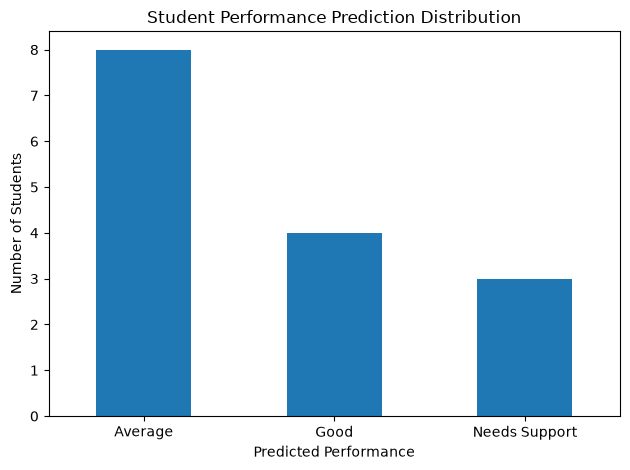

In [7]:
import matplotlib.pyplot as plt

# Tuma file re actual column name
col_name = "Performance_Category"

if col_name in df.columns:
    print("Predicted Performance Distribution:")
    print(df[col_name].value_counts())
    
    df[col_name].value_counts().plot(
        kind="bar",
        title="Student Performance Prediction Distribution"
    )
    plt.xlabel("Predicted Performance")
    plt.ylabel("Number of Students")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Column not found. Available columns:")
    print(df.columns.tolist())

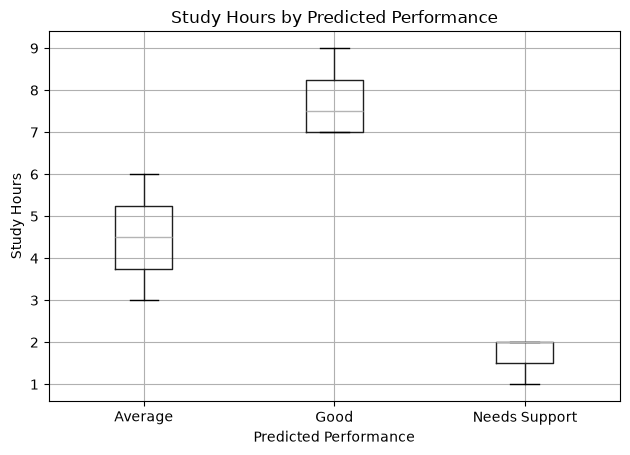

✅ Graph saved!


In [9]:
import matplotlib.pyplot as plt

# Tuma actual columns
study_col = "Study_Hours"
perf_col = "Performance_Category"

if study_col in df.columns and perf_col in df.columns:
    df.boxplot(
        column=study_col,
        by=perf_col
    )
    plt.title("Study Hours by Predicted Performance")
    plt.suptitle("")
    plt.xlabel("Predicted Performance")
    plt.ylabel("Study Hours")
    plt.tight_layout()
    plt.savefig("day25_study_hours_by_performance.png")
    plt.show()
    print("✅ Graph saved!")
else:
    print("Available columns:")
    print(df.columns.tolist())

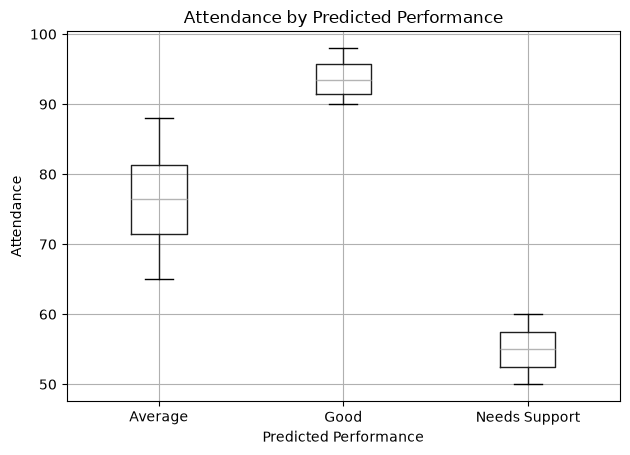

✅ Graph saved!


In [14]:
import matplotlib.pyplot as plt

df.boxplot(
    column="Attendance",
    by="Performance_Category"
)
plt.title("Attendance by Predicted Performance")
plt.suptitle("")
plt.xlabel("Predicted Performance")
plt.ylabel("Attendance")
plt.tight_layout()
plt.show()
print("✅ Graph saved!")

Correlation Matrix:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
Study_Hours,1.000000,0.982458,0.991163,0.993752
Attendance,0.982458,1.000000,0.977244,0.980231
Previous_Marks,0.991163,0.977244,1.000000,0.998455
Final_Marks,0.993752,0.980231,0.998455,1.000000


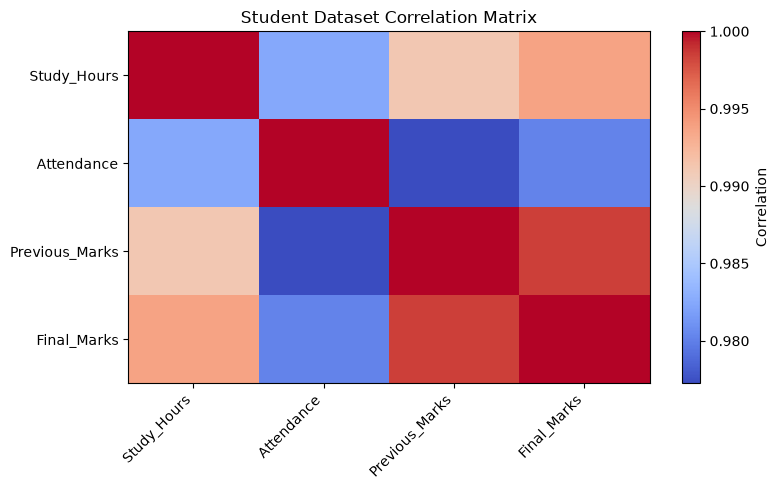

In [15]:
numeric_df = df.select_dtypes(include=np.number)

if not numeric_df.empty:
    correlation = numeric_df.corr()

    print("Correlation Matrix:")
    display(correlation)

    plt.figure(figsize=(8, 5))
    plt.imshow(correlation, cmap="coolwarm", aspect="auto")
    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(range(len(correlation.columns)), correlation.columns)

    plt.title("Student Dataset Correlation Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns available.")

In [16]:
output_dir = Path.cwd()

summary = df.describe(include="all").transpose()
summary.to_csv(output_dir / "day25_prediction_summary.csv")

df.isnull().sum().to_csv(
    output_dir / "day25_dataset_quality.csv",
    header=["missing_values"]
)

if not numeric_df.empty:
    numeric_df.corr().to_csv(
        output_dir / "day25_correlation_matrix.csv"
    )

print("Analysis results saved successfully!")
print("Output folder:", output_dir)

Analysis results saved successfully!
Output folder: c:\Users\Bagmita\OneDrive\Desktop\Project


In [17]:
report = f"""
DAY 25 PROJECT REPORT
Project Name: Student Performance Prediction System

Dataset rows: {df.shape[0]}
Dataset columns: {df.shape[1]}

Available columns:
{df.columns.tolist()}

Missing values:
{df.isnull().sum().to_string()}

Duplicate rows: {df.duplicated().sum()}

Note:
This dataset contains predicted performance labels.
Actual ground-truth labels are not available in the
provided columns, so model accuracy and other
classification evaluation metrics cannot yet be verified.
"""

report_path = output_dir / "day25_student_performance_analysis_report.txt"
report_path.write_text(report, encoding="utf-8")

print(report)
print("Report saved:", report_path.name)


DAY 25 PROJECT REPORT
Project Name: Student Performance Prediction System

Dataset rows: 15
Dataset columns: 7

Available columns:
['Study_Hours', 'Attendance', 'Previous_Marks', 'Final_Marks', 'Performance_Category', 'Model_Predicted_Category', 'Correct_Prediction']

Missing values:
Study_Hours                  0
Attendance                   0
Previous_Marks               0
Final_Marks                  0
Performance_Category         0
Model_Predicted_Category     0
Correct_Prediction          12

Duplicate rows: 0

Note:
This dataset contains predicted performance labels.
Actual ground-truth labels are not available in the
provided columns, so model accuracy and other
classification evaluation metrics cannot yet be verified.

Report saved: day25_student_performance_analysis_report.txt


In [18]:
files_to_check = [
    "day25_prediction_summary.csv",
    "day25_dataset_quality.csv",
    "day25_correlation_matrix.csv",
    "day25_student_performance_analysis_report.txt"
]

print("DAY 25 OUTPUT VERIFICATION")
print("-" * 40)

for filename in files_to_check:
    path = output_dir / filename
    if path.exists():
        print(f"[OK] {filename}")
    else:
        print(f"[MISSING] {filename}")

print("\nDay 25 analysis completed!")

DAY 25 OUTPUT VERIFICATION
----------------------------------------
[OK] day25_prediction_summary.csv
[OK] day25_dataset_quality.csv
[OK] day25_correlation_matrix.csv
[OK] day25_student_performance_analysis_report.txt

Day 25 analysis completed!
